# Email_Detection 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# load the dataset
df = pd.read_csv(r"C:\Users\asusvivobook\Desktop\FSDS\ML Practicals\Navie Bayes\Spam Email\emails.csv")

In [3]:
# check the overall dataset
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Shape: (5728, 2)

Columns:
Index(['text', 'spam'], dtype='str')

Data Types:
text      str
spam    int64
dtype: object

Missing Values:
text    0
spam    0
dtype: int64


In [4]:
print("Duplicate rows:", df.duplicated().sum())



Duplicate rows: 33


In [5]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (5695, 2)


In [7]:
print("\nSpam Distribution:")
print(df["spam"].value_counts())


Spam Distribution:
spam
0    4327
1    1368
Name: count, dtype: int64


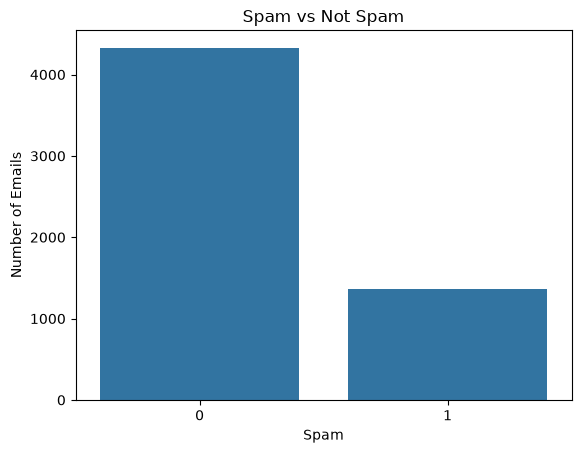

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="spam", data=df)

plt.title("Spam vs Not Spam")
plt.xlabel("Spam")
plt.ylabel("Number of Emails")

plt.show()

In [9]:
X = df["text"]
y = df["spam"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5695,)
y shape: (5695,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4556,)
Testing data: (1139,)


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (4556, 5000)
Testing TF-IDF shape: (1139, 5000)


In [12]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


In [13]:
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")
print(y_pred[:20])

Predictions completed!
[0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 1 0 0 0]


In [14]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.9833187006145742
Accuracy Percentage: 98.33187006145742


In [15]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[861   4]
 [ 15 259]]


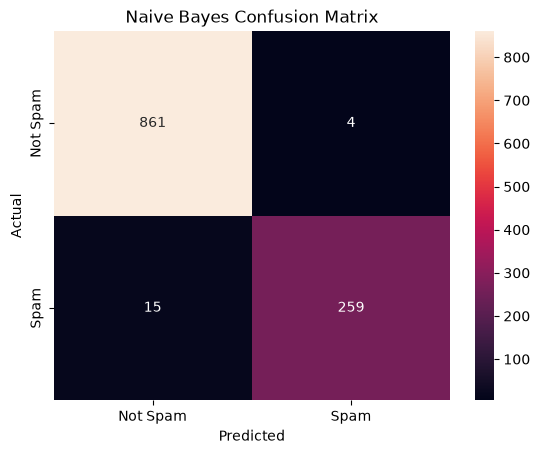

In [16]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes Confusion Matrix")

plt.show()

In [17]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       865
           1       0.98      0.95      0.96       274

    accuracy                           0.98      1139
   macro avg       0.98      0.97      0.98      1139
weighted avg       0.98      0.98      0.98      1139



In [18]:
new_email = [
    "Congratulations! You have won a free lottery prize. Click now to claim."
]

new_email_tfidf = vectorizer.transform(new_email)

prediction = model.predict(new_email_tfidf)

if prediction[0] == 1:
    print("Prediction: Spam")
else:
    print("Prediction: Not Spam")

Prediction: Spam


In [19]:
new_email = [
    "Hi Harshitha, your interview is scheduled for tomorrow at 10 AM."
]

new_email_tfidf = vectorizer.transform(new_email)

prediction = model.predict(new_email_tfidf)

if prediction[0] == 1:
    print("Prediction: Spam")
else:
    print("Prediction: Not Spam")

Prediction: Not Spam


In [20]:
import joblib

joblib.dump(model, "model.pkl")
joblib.dump(vectorizer, "vectorizer.pkl")

print("Model saved successfully!")
print("Vectorizer saved successfully!")

Model saved successfully!
Vectorizer saved successfully!
